# FridayNights - two layer fuzzy system

For our project FridayNights we want to recommend events based on an event database and a survey.
Here I try a two layer fuzzy system with skfuzzy. Layer 1 takes the energy level and the group and gives a readiness value.
A lambda cut then picks which event bins to look at, and layer 2 matches readiness with the event intensity to rank the events.
With two layers we need 9 + 9 rules instead of 27 for one system with three inputs.

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl


# makes one rule per line of a rule table: (input1, input2): output
def build_rules(table, in1, in2, out):
    return [ctrl.Rule(in1[a] & in2[b], out[c]) for (a, b), c in table.items()]

## Group load

In [26]:
# turn the group from the survey into one number from 0 to 10
# adults count 1, kids 2 (bedtimes, age limits), pets 1.5 (not allowed everywhere)
def group_load(adults, kids=0, pets=0):
    return min(adults * 1 + kids * 2 + pets * 1.5, 10)


# (adults, kids, pets)
for g in [(1, 0, 0), (2, 0, 0), (4, 0, 0), (2, 2, 0), (2, 2, 1)]:
    print(g, group_load(*g))

(1, 0, 0) 1.0
(2, 0, 0) 2.0
(4, 0, 0) 4.0
(2, 2, 0) 6.0
(2, 2, 1) 7.5


## Layer 1: energy + group load -> readiness

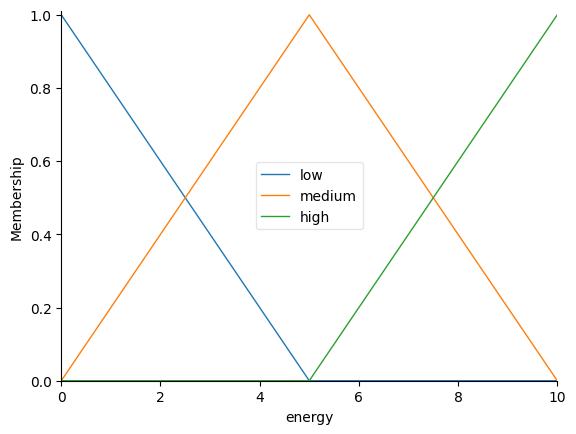

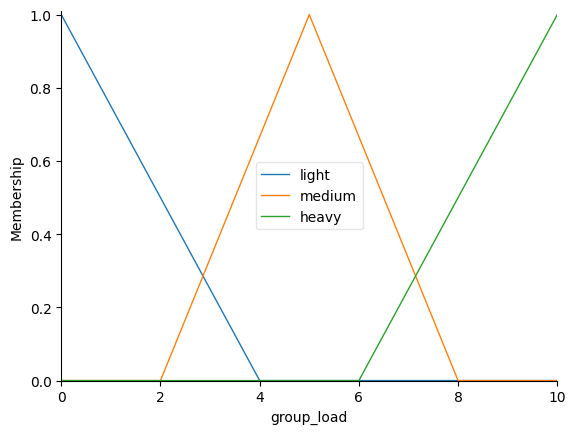

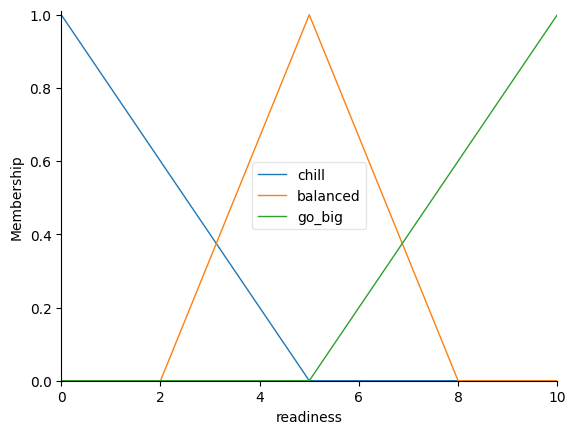

In [27]:
# all three variables go from 0 to 10
universe = np.linspace(0, 10, 101)

energy = ctrl.Antecedent(universe, 'energy')
group = ctrl.Antecedent(universe, 'group_load')
readiness = ctrl.Consequent(universe, 'readiness')

energy['low'] = fuzz.trimf(universe, [0, 0, 5])
energy['medium'] = fuzz.trimf(universe, [0, 5, 10])
energy['high'] = fuzz.trimf(universe, [5, 10, 10])

group['light'] = fuzz.trimf(universe, [0, 0, 4])
group['medium'] = fuzz.trimf(universe, [2, 5, 8])
group['heavy'] = fuzz.trimf(universe, [6, 10, 10])

readiness['chill'] = fuzz.trimf(universe, [0, 0, 5])
readiness['balanced'] = fuzz.trimf(universe, [2, 5, 8])
readiness['go_big'] = fuzz.trimf(universe, [5, 10, 10])

energy.view()
group.view()
readiness.view()

In [28]:
layer1_table = {
    # (energy, group_load): readiness
    ('low',    'light'):  'chill',
    ('low',    'medium'): 'chill',
    ('low',    'heavy'):  'balanced',
    ('medium', 'light'):  'chill',
    ('medium', 'medium'): 'balanced',
    ('medium', 'heavy'):  'go_big',
    ('high',   'light'):  'go_big',
    ('high',   'medium'): 'go_big',
    ('high',   'heavy'):  'go_big',
}

readiness = 6.88


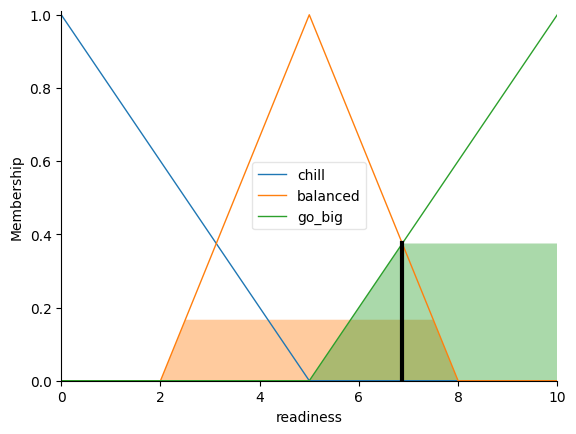

In [29]:
layer1_sim = ctrl.ControlSystemSimulation(
    ctrl.ControlSystem(build_rules(layer1_table, energy, group, readiness)))


def readiness_for(energy_level, load):
    layer1_sim.input['energy'] = energy_level
    layer1_sim.input['group_load'] = load
    layer1_sim.compute()
    return layer1_sim.output['readiness']


# test: energy 7, 2 adults + 2 kids + a dog
r = readiness_for(7, group_load(2, 2, 1))
print('readiness =', round(r, 2))
readiness.view(sim=layer1_sim)

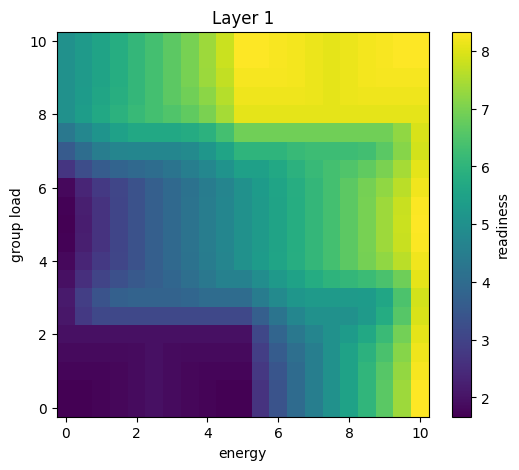

In [30]:
# readiness for every combination of energy and group load
grid = np.linspace(0, 10, 21)
surface = np.array([[readiness_for(e, g) for e in grid] for g in grid])

fig, ax = plt.subplots(figsize=(6, 5))
mesh = ax.pcolormesh(grid, grid, surface, shading='auto')
fig.colorbar(mesh, ax=ax, label='readiness')
ax.set_xlabel('energy')
ax.set_ylabel('group load')
ax.set_title('Layer 1')
plt.show()

## Lambda cut

In [31]:
BINS = ['chill', 'balanced', 'go_big']


# membership of the readiness value in each bin
# a bin is kept if its membership is >= lam, if no bin is kept we take the best one
def readiness_bins(r, lam):
    ms = np.array([fuzz.interp_membership(universe, readiness[b].mf, r) for b in BINS])
    keep = fuzz.lambda_cut(ms, lam)
    if not keep.any():
        keep[ms.argmax()] = 1
    memberships = {b: round(float(m), 2) for b, m in zip(BINS, ms)}
    return memberships, [b for b, k in zip(BINS, keep) if k]


for lam in [0.2, 0.4, 0.8]:
    print('readiness 6.5, lambda', lam, '->', readiness_bins(6.5, lam))

readiness 6.5, lambda 0.2 -> ({'chill': 0.0, 'balanced': 0.5, 'go_big': 0.3}, ['balanced', 'go_big'])
readiness 6.5, lambda 0.4 -> ({'chill': 0.0, 'balanced': 0.5, 'go_big': 0.3}, ['balanced'])
readiness 6.5, lambda 0.8 -> ({'chill': 0.0, 'balanced': 0.5, 'go_big': 0.3}, ['balanced'])


## Events

In [32]:
# small made up event list, intensity = how loud / busy / late it is (0-10)
EVENTS = [
    {'name': 'Board game café',     'bin': 'chill',    'intensity': 2.0},
    {'name': 'Cinema',              'bin': 'chill',    'intensity': 3.0},
    {'name': 'Museum late opening', 'bin': 'chill',    'intensity': 3.5},
    {'name': 'Jazz bar',            'bin': 'balanced', 'intensity': 4.5},
    {'name': 'Food truck festival', 'bin': 'balanced', 'intensity': 5.0},
    {'name': 'Bowling',             'bin': 'balanced', 'intensity': 5.5},
    {'name': 'Escape room',         'bin': 'balanced', 'intensity': 6.0},
    {'name': 'Rock concert',        'bin': 'go_big',   'intensity': 8.0},
    {'name': 'Pub crawl',           'bin': 'go_big',   'intensity': 8.5},
    {'name': 'Club night',          'bin': 'go_big',   'intensity': 9.5},
]

## Layer 2: readiness + intensity -> match

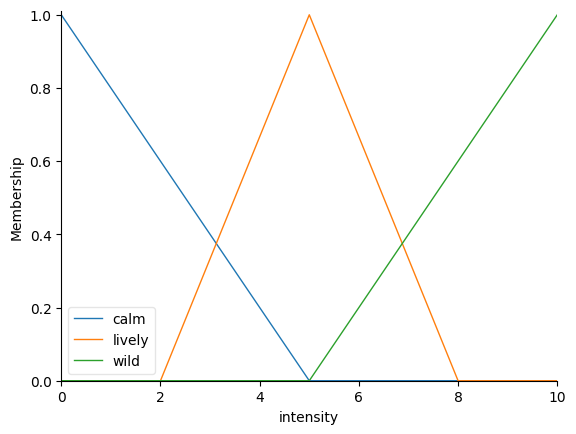

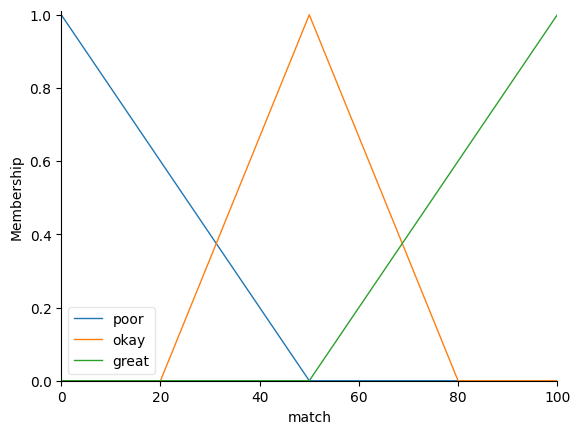

In [33]:
# readiness is an input now, so it needs a new Antecedent with the same terms
readiness_in = ctrl.Antecedent(universe, 'readiness')
intensity = ctrl.Antecedent(universe, 'intensity')
match = ctrl.Consequent(np.linspace(0, 100, 101), 'match')

readiness_in['chill'] = fuzz.trimf(universe, [0, 0, 5])
readiness_in['balanced'] = fuzz.trimf(universe, [2, 5, 8])
readiness_in['go_big'] = fuzz.trimf(universe, [5, 10, 10])

intensity['calm'] = fuzz.trimf(universe, [0, 0, 5])
intensity['lively'] = fuzz.trimf(universe, [2, 5, 8])
intensity['wild'] = fuzz.trimf(universe, [5, 10, 10])

match['poor'] = fuzz.trimf(match.universe, [0, 0, 50])
match['okay'] = fuzz.trimf(match.universe, [20, 50, 80])
match['great'] = fuzz.trimf(match.universe, [50, 100, 100])

intensity.view()
match.view()

In [34]:
layer2_table = {
    # (readiness, intensity): match
    ('chill',    'calm'):   'great',
    ('chill',    'lively'): 'okay',
    ('chill',    'wild'):   'poor',
    ('balanced', 'calm'):   'okay',
    ('balanced', 'lively'): 'great',
    ('balanced', 'wild'):   'okay',
    ('go_big',   'calm'):   'poor',
    ('go_big',   'lively'): 'okay',
    ('go_big',   'wild'):   'great',
}

match = 72.4


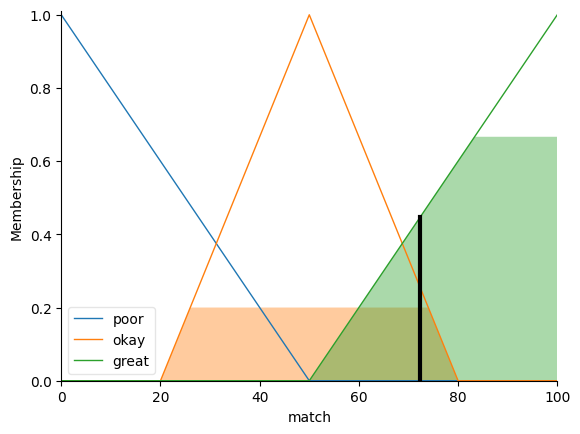

In [35]:
layer2_sim = ctrl.ControlSystemSimulation(
    ctrl.ControlSystem(build_rules(layer2_table, readiness_in, intensity, match)))


def match_score(r, event_intensity):
    layer2_sim.input['readiness'] = r
    layer2_sim.input['intensity'] = event_intensity
    layer2_sim.compute()
    return layer2_sim.output['match']


# test: readiness 6 and the escape room (intensity 6)
print('match =', round(match_score(6.0, 6.0), 1))
match.view(sim=layer2_sim)

## Recommend

In [36]:
# survey -> group load -> layer 1 -> lambda cut -> layer 2 -> events sorted by match
def recommend(energy_level, adults, kids=0, pets=0, lam=0.5, top=5, show=True):
    load = group_load(adults, kids, pets)
    r = readiness_for(energy_level, load)
    memberships, bins = readiness_bins(r, lam)

    candidates = [e for e in EVENTS if e['bin'] in bins]
    ranked = sorted([(match_score(r, e['intensity']), e) for e in candidates],
                    key=lambda x: x[0], reverse=True)

    if show:
        print('energy', energy_level, '| group load', load, '| readiness', round(r, 2))
        print('memberships', memberships, '| lambda', lam, '->', bins)
        for score, e in ranked[:top]:
            print('  ', round(score, 1), e['name'])
    return ranked[:top]

## three different users

Same lambda (0.5) for everyone.

In [37]:
users = [
    ('Tired parents with 2 kids and a dog', dict(energy_level=3, adults=2, kids=2, pets=1)),
    ('Couple, medium energy',               dict(energy_level=5.5, adults=2)),
    ('Four friends, full of energy',        dict(energy_level=9, adults=4)),
]

for title, survey in users:
    print('---', title)
    recommend(**survey, lam=0.5)
    print()

--- Tired parents with 2 kids and a dog
energy 3 | group load 7.5 | readiness 5.66
memberships {'chill': 0.0, 'balanced': 0.78, 'go_big': 0.13} | lambda 0.5 -> ['balanced']
   76.0 Food truck festival
   76.0 Bowling
   72.4 Escape room
   71.3 Jazz bar

--- Couple, medium energy
energy 5.5 | group load 2.0 | readiness 3.09
memberships {'chill': 0.38, 'balanced': 0.36, 'go_big': 0.0} | lambda 0.5 -> ['chill']
   63.1 Board game café
   63.1 Cinema
   62.4 Museum late opening

--- Four friends, full of energy
energy 9 | group load 4.0 | readiness 7.24
memberships {'chill': 0.0, 'balanced': 0.25, 'go_big': 0.45} | lambda 0.5 -> ['go_big']
   67.2 Rock concert
   67.2 Pub crawl
   67.2 Club night



## Changing lambda

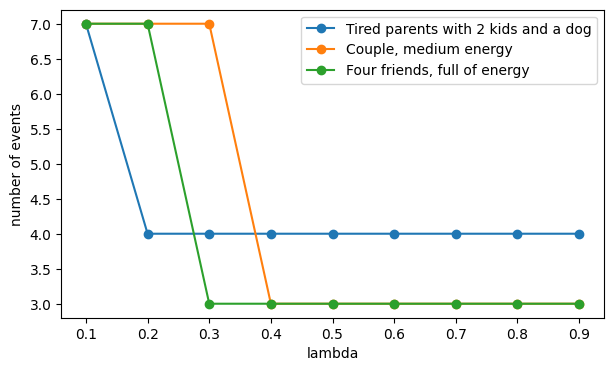

--- Couple, medium energy | lambda 0.2
energy 5.5 | group load 2.0 | readiness 3.09
memberships {'chill': 0.38, 'balanced': 0.36, 'go_big': 0.0} | lambda 0.2 -> ['chill', 'balanced']
   63.1 Board game café
   63.1 Cinema
   62.4 Museum late opening
   62.4 Jazz bar
   62.4 Food truck festival

--- Couple, medium energy | lambda 0.8
energy 5.5 | group load 2.0 | readiness 3.09
memberships {'chill': 0.38, 'balanced': 0.36, 'go_big': 0.0} | lambda 0.8 -> ['chill']
   63.1 Board game café
   63.1 Cinema
   62.4 Museum late opening



In [38]:
# how many events are left for each user when lambda goes up
lambdas = np.round(np.linspace(0.1, 0.9, 9), 1)

fig, ax = plt.subplots(figsize=(7, 4))
for title, survey in users:
    counts = [len(recommend(**survey, lam=lam, top=len(EVENTS), show=False)) for lam in lambdas]
    ax.plot(lambdas, counts, 'o-', label=title)
ax.set_xlabel('lambda')
ax.set_ylabel('number of events')
ax.legend()
plt.show()

# same user with a low and a high lambda
title, survey = users[1]
for lam in [0.2, 0.8]:
    print('---', title, '| lambda', lam)
    recommend(**survey, lam=lam)
    print()